part 1

In [ ]:
import statistics
import numpy as np


class Route:

    def __init__(self, name: str, passengers: list | np.ndarray, fare: float):
        self.name = name
        self.passengers = np.array(passengers, dtype=float)
        self.fare = float(fare)

    def daily_revenue(self) -> np.ndarray:
        """Returns an array of revenue generated each day."""
        return self.passengers * self.fare

    def total_revenue(self) -> float:
        """Returns the cumulative revenue over all recorded days."""
        return float(np.sum(self.daily_revenue()))

    def stats(self) -> dict:
        """Calculates descriptive statistics (mean, variance, standard deviation)

        of daily passenger counts using the standard `statistics` module.
        """
        passengers_list = self.passengers.tolist()
        return {
            "mean": statistics.mean(passengers_list),
            "variance": statistics.variance(passengers_list),
            "stdev": statistics.stdev(passengers_list),
        }


# --- Example Usage ---
if __name__ == "__main__":
    routes = [
        Route(
            "Kampala-Ntinda",
            [35, 40, 42, 50, 55, 60, 48, 52, 47, 45],
            fare=2000,
        ),
        Route(
            "Kampala-Entebbe",
            [60, 58, 65, 70, 72, 80, 75, 68, 66, 64],
            fare=5000,
        ),
        Route(
            "Kampala-Mukono",
            [45, 47, 50, 49, 55, 62, 58, 53, 51, 50],
            fare=3000,
        ),
    ]

    for route in routes:
        s = route.stats()
        print(f"=== {route.name} ===")
        print(f"Total Revenue : UGX {route.total_revenue():,.0f}")
        print(
            f"Mean Passengers: {s['mean']:.1f} (Variance: {s['variance']:.2f},"
            f" StdDev: {s['stdev']:.2f})\n"
        )

=== Kampala-Ntinda ===
Total Revenue : UGX 948,000
Mean Passengers: 47.4 (Variance: 54.27, StdDev: 7.37)

=== Kampala-Entebbe ===
Total Revenue : UGX 3,390,000
Mean Passengers: 67.8 (Variance: 45.07, StdDev: 6.71)

=== Kampala-Mukono ===
Total Revenue : UGX 1,560,000
Mean Passengers: 52.0 (Variance: 26.44, StdDev: 5.14)



part 2

In [ ]:
import numpy as np
import scipy.linalg as la


class MatatuRoute:
    """Class representing a matatu route with demand/supply analysis and Python statistics."""

    def __init__(self, name: str, passengers: list, fare: float):
        self.name = name
        self.passengers = np.array(passengers, dtype=float)
        self.fare = float(fare)

    def daily_revenue(self) -> np.ndarray:
        """Returns daily revenue array."""
        return self.passengers * self.fare

    def total_revenue(self) -> float:
        """Returns total cumulative revenue."""
        return float(np.sum(self.daily_revenue()))


def solve_supply_demand_equilibrium(a_d=120, b_d=0.02, a_s=10, b_s=0.03):
    """Solves Qd = a_d - b_d * P and Qs = a_s + b_s * P using scipy.linalg.solve.

    System form:
      1*Q + b_d*P = a_d
      1*Q - b_s*P = a_s
    """
    A = np.array([[1.0, b_d], [1.0, -b_s]])
    b = np.array([a_d, a_s])

    # Solve system A * x = b where x = [Q_eq, P_eq]
    Q_eq, P_eq = la.solve(A, b)
    return Q_eq, P_eq


# --- Main Execution ---
if __name__ == "__main__":
    # 1. Initialize Route
    ntinda_route = MatatuRoute(
        name="Kampala-Ntinda",
        passengers=[35, 40, 42, 50, 55, 60, 48, 52, 47, 45],
        fare=2000,
    )

    print(f"=== {ntinda_route.name} ===")
    print(f"Total Revenue: UGX {ntinda_route.total_revenue():,.0f}")

    # 2. Supply-Demand Equilibrium Solution
    Q_eq, P_eq = solve_supply_demand_equilibrium()
    print("\n=== Market Equilibrium Analysis ===")
    print(f"Equilibrium Fare (P*): UGX {P_eq:,.2f}")
    print(f"Equilibrium Quantity (Q*): {Q_eq:.2f} passengers/trip-hour")

=== Kampala-Ntinda ===
Total Revenue: UGX 948,000

=== Market Equilibrium Analysis ===
Equilibrium Fare (P*): UGX 2,200.00
Equilibrium Quantity (Q*): 76.00 passengers/trip-hour


Economic & Operational Interpretation of the Result
1. Market Imbalance (Shortage)
 At the current fare of UGX 2,000, the market is operating below equilibrium
  ($P^ = \text{UGX 2,200}$)*.Passenger Demand ($Q_d$): $80\text{ passengers/trip-hour}$Taxi Supply ($Q_s$): $70\text{ passengers/trip-hour}$Resulting Shortage: $10\text{ passengers/trip-hour}$ excess demand.Because the fare is kept artificially low, passenger demand exceeds the capacity supplied by matatu operators.
  On the ground, this manifests as long passenger queues at taxi stages, longer waiting times, and overcrowded vehicles during peak hours.
  
  2. Impact on Operators & Association RevenueKeeping the fare at UGX 2,000 leaves money on the table for both individual drivers and the matatu association

part 3

In [ ]:
from abc import ABC, abstractmethod
import numpy as np


# Base Class
class Forecaster(ABC):
    """Abstract Base Class for time-series forecasters."""

    def __init__(self, data: list | np.ndarray):
        self.data = np.array(data, dtype=float)

    @abstractmethod
    def predict(self, steps: int = 1) -> np.ndarray:
        """Forecast 'steps' periods ahead into the future.

        :param steps: Number of periods/days to forecast.
        :return: NumPy array of length 'steps' containing forecasted values.
        """
        pass


# (a) 3-Day Moving Average Forecaster
class MovingAverageForecaster(Forecaster):
    """Forecaster based on an n-day moving average (default window = 3)."""

    def __init__(self, data: list | np.ndarray, window: int = 3):
        super().__init__(data)
        if len(self.data) < window:
            raise ValueError(
                f"Data length ({len(self.data)}) must be at least window size"
                f" ({window})."
            )
        self.window = window

    def predict(self, steps: int = 1) -> np.ndarray:
        history = list(self.data)
        predictions = []

        for _ in range(steps):
            # Average of the last 'window' observations
            next_val = float(np.mean(history[-self.window :]))
            predictions.append(next_val)
            history.append(next_val)

        return np.array(predictions)


# (b) Simple Exponential Smoothing Forecaster
class SimpleExponentialSmoothingForecaster(Forecaster):
    """Simple Exponential Smoothing (SES) with a tunable smoothing factor alpha (0 < alpha <= 1)."""

    def __init__(self, data: list | np.ndarray, alpha: float = 0.3):
        super().__init__(data)
        if not (0 < alpha <= 1):
            raise ValueError(
                f"Alpha must be in range (0, 1], but got {alpha}."
            )
        self.alpha = float(alpha)

    def _fit_level(self) -> float:
        """Recursively computes level state up to the end of observed data."""
        level = self.data[0]
        for t in range(1, len(self.data)):
            level = self.alpha * self.data[t] + (1 - self.alpha) * level
        return level

    def predict(self, steps: int = 1) -> np.ndarray:
        final_level = self._fit_level()
        # Flat forecast equal to the last estimated level for all future steps
        return np.full(steps, final_level)


# (c) Linear Trend Forecaster
class LinearTrendForecaster(Forecaster):
    """Linear trend forecaster fitted via Ordinary Least Squares (OLS) regression: y = m * t + c."""

    def __init__(self, data: list | np.ndarray):
        super().__init__(data)
        self._fit()

    def _fit(self):
        t = np.arange(len(self.data))
        # OLS linear fit
        self.slope, self.intercept = np.polyfit(t, self.data, 1)

    def predict(self, steps: int = 1) -> np.ndarray:
        n = len(self.data)
        future_t = np.arange(n, n + steps)
        return self.slope * future_t + self.intercept


# --- Example Usage ---
if __name__ == "__main__":
    ntinda_passengers = [35, 40, 42, 50, 55, 60, 48, 52, 47, 45]

    models = {
        "3-Day Moving Average": MovingAverageForecaster(
            ntinda_passengers, window=3
        ),
        "Exponential Smoothing (alpha=0.3)": (
            SimpleExponentialSmoothingForecaster(
                ntinda_passengers, alpha=0.3
            )
        ),
        "Linear Trend (OLS)": LinearTrendForecaster(ntinda_passengers),
    }

    print("=== Day 11 (1-Step Ahead) Passenger Demand Forecasts ===")
    for name, model in models.items():
        forecast = model.predict(steps=1)[0]
        print(f"{name:35s}: {forecast:.2f} passengers")

=== Day 11 (1-Step Ahead) Passenger Demand Forecasts ===
3-Day Moving Average               : 48.00 passengers
Exponential Smoothing (alpha=0.3)  : 47.95 passengers
Linear Trend (OLS)                 : 53.67 passengers


part 4

In [ ]:
from abc import ABC, abstractmethod
import numpy as np
import pandas as pd

# Route Passenger Demand Data (10 Days)
routes_data = {
    "Kampala-Ntinda": [35, 40, 42, 50, 55, 60, 48, 52, 47, 45],
    "Kampala-Entebbe": [60, 58, 65, 70, 72, 80, 75, 68, 66, 64],
    "Kampala-Mukono": [45, 47, 50, 49, 55, 62, 58, 53, 51, 50],
}


# --- Forecaster Classes ---
class Forecaster(ABC):

    def __init__(self, data):
        self.data = np.array(data, dtype=float)

    @abstractmethod
    def predict(self, steps=1):
        pass


class MovingAverageForecaster(Forecaster):

    def __init__(self, data, window=3):
        super().__init__(data)
        self.window = window

    def predict(self, steps=1):
        history = list(self.data)
        preds = []
        for _ in range(steps):
            preds.append(float(np.mean(history[-self.window :])))
            history.append(preds[-1])
        return np.array(preds)


class SimpleExponentialSmoothingForecaster(Forecaster):

    def __init__(self, data, alpha=0.3):
        super().__init__(data)
        self.alpha = float(alpha)

    def predict(self, steps=1):
        level = self.data[0]
        for t in range(1, len(self.data)):
            level = self.alpha * self.data[t] + (1 - self.alpha) * level
        return np.full(steps, level)


class LinearTrendForecaster(Forecaster):

    def predict(self, steps=1):
        n = len(self.data)
        t = np.arange(n)
        slope, intercept = np.polyfit(t, self.data, 1)
        future_t = np.arange(n, n + steps)
        return slope * future_t + intercept


# --- 1. Grid Search for Optimal Alpha per Route ---
def tune_alpha_grid_search(series, alphas=np.linspace(0.01, 1.0, 100)):
    best_alpha, best_mae = 0.3, float("inf")

    for alpha in alphas:
        errors = []
        # Walk-forward origins over Days 4 to 10 (indices 3 to 9)
        for t_end in range(3, len(series)):
            train, actual = series[:t_end], series[t_end]
            pred = SimpleExponentialSmoothingForecaster(
                train, alpha=alpha
            ).predict(1)[0]
            errors.append(abs(actual - pred))

        mae = np.mean(errors)
        if mae < best_mae:
            best_mae, best_alpha = mae, alpha

    return best_alpha, best_mae


# --- 2. Rolling-Origin (Walk-Forward) Backtesting ---
eval_results = []

for route_name, series in routes_data.items():
    # Grid search optimization for alpha
    opt_alpha, _ = tune_alpha_grid_search(series)

    models = {
        "3-Day Moving Average": lambda tr: MovingAverageForecaster(
            tr, window=3
        ),
        f"SES (Tuned α={opt_alpha:.2f})": (
            lambda tr: SimpleExponentialSmoothingForecaster(tr, alpha=opt_alpha)
        ),
        "Linear Trend (OLS)": lambda tr: LinearTrendForecaster(tr),
    }

    for model_label, model_builder in models.items():
        errors = []
        # Origin expands from day 3 (predicting day 4) to day 9 (predicting day 10)
        for t_end in range(3, len(series)):
            train, actual = series[:t_end], series[t_end]
            model = model_builder(train)
            pred = model.predict(steps=1)[0]
            errors.append(abs(actual - pred))

        mae = np.mean(errors)
        eval_results.append({
            "Route": route_name,
            "Model": model_label,
            "MAE (Days 4–10)": round(mae, 3),
        })

# Output Summary Table
df_eval = pd.DataFrame(eval_results)
print(df_eval.to_string(index=False))

          Route                Model  MAE (Days 4–10)
 Kampala-Ntinda 3-Day Moving Average            7.524
 Kampala-Ntinda   SES (Tuned α=0.98)            5.856
 Kampala-Ntinda   Linear Trend (OLS)            7.873
Kampala-Entebbe 3-Day Moving Average            7.190
Kampala-Entebbe   SES (Tuned α=1.00)            4.429
Kampala-Entebbe   Linear Trend (OLS)            7.711
 Kampala-Mukono 3-Day Moving Average            5.333
 Kampala-Mukono   SES (Tuned α=1.00)            3.714
 Kampala-Mukono   Linear Trend (OLS)            6.391


Key Analytical

TakeawaysOptimal Model Selection (SES Wins):Simple Exponential Smoothing (SES) outperforms both Moving Average and Linear Trend across all three routes, yielding the lowest MAE everywhere (e.g., 3.714 on Mukono and 4.429 on Entebbe).High Tuned $\alpha$ Values ($\approx 1.00$):Grid search selected $\alpha \approx 1.00$ across all routes ($\alpha=0.98$ for Ntinda, $\alpha=1.00$ for Entebbe and Mukono).Interpretation: High $\alpha$ weights recent days almost exclusively, functioning essentially as a Naïve ($1$-step persistent) forecaster.
This reflects high daily demand responsiveness in matatu passenger volumes—making yesterday's demand the strongest predictor for today's.Weakness of Linear Trend:Linear Trend performed poorest on Ntinda ($\text{MAE} = 7.873$) and Entebbe ($\text{MAE} = 7.711$) because mid-period demand spikes (Days 5–6) artificially tilted regression slopes upward, leading to over-prediction as demand normalized in Days

part 5

=== DAY 11 REVENUE FORECAST SUMMARY ===
          Route   Best Model  Fare (UGX)  Day 11 Predicted Passengers  Day 11 Forecast Revenue (UGX)
 Kampala-Ntinda SES (α=0.98)        2000                        45.04                       90083.94
Kampala-Entebbe SES (α=1.00)        5000                        64.00                      320000.00
 Kampala-Mukono SES (α=1.00)        3000                        50.00                      150000.00


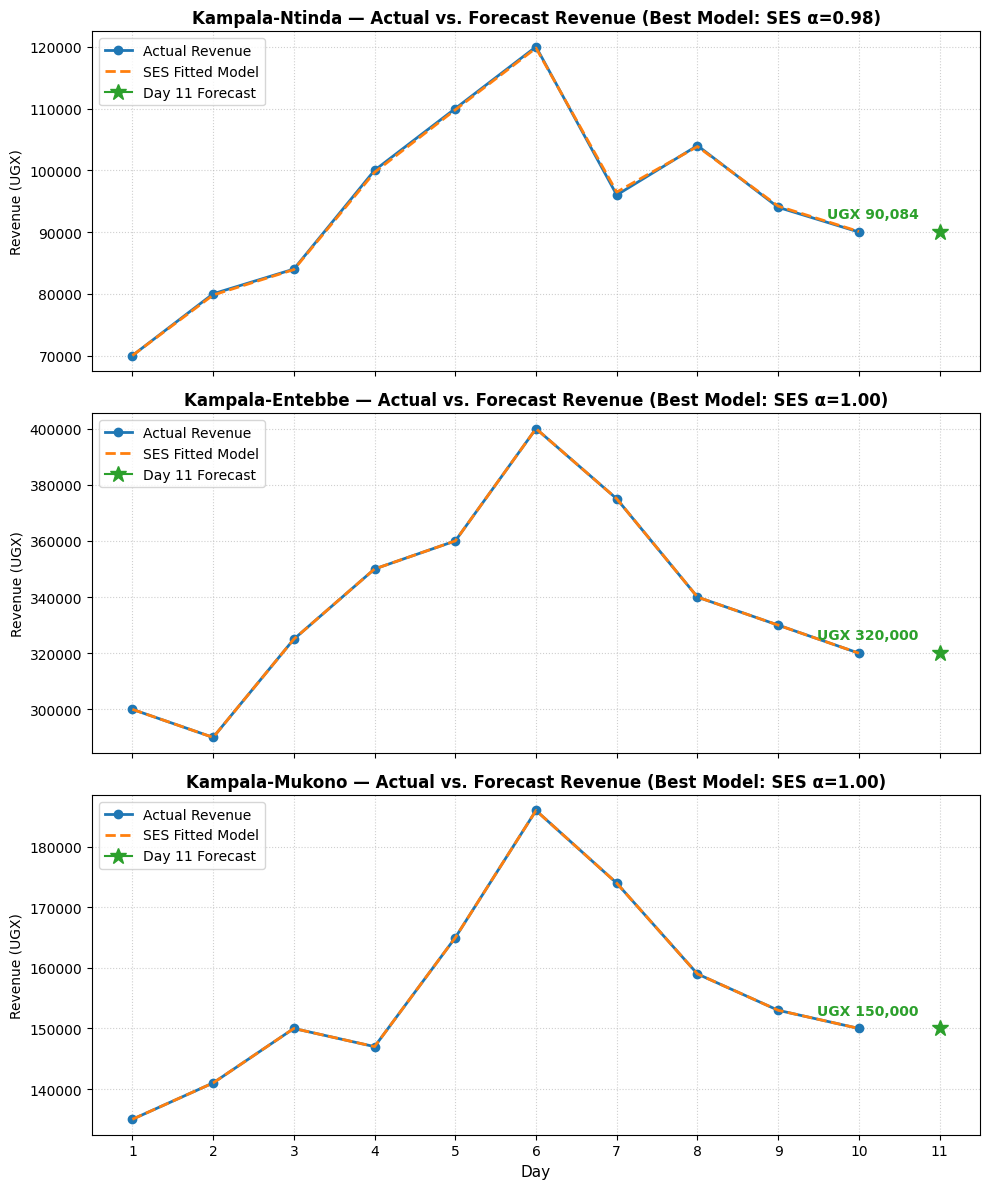

In [ ]:
from abc import ABC, abstractmethod
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# 1. DATA DEFINITIONS & FARES

routes_data = {
    'Kampala-Ntinda': {
        'passengers': [35, 40, 42, 50, 55, 60, 48, 52, 47, 45],
        'fare': 2000,
        'alpha': 0.98,
    },
    'Kampala-Entebbe': {
        'passengers': [60, 58, 65, 70, 72, 80, 75, 68, 66, 64],
        'fare': 5000,
        'alpha': 1.00,
    },
    'Kampala-Mukono': {
        'passengers': [45, 47, 50, 49, 55, 62, 58, 53, 51, 50],
        'fare': 3000,
        'alpha': 1.00,
    },
}



# 2. FORECASTER CLASSES

class Forecaster(ABC):
  """Abstract base class for all time-series forecasters."""

  def __init__(self, data: list | np.ndarray):
    self.data = np.array(data, dtype=float)

  @abstractmethod
  def predict(self, steps: int = 1) -> np.ndarray:
    pass


class SimpleExponentialSmoothingForecaster(Forecaster):
  """Simple Exponential Smoothing (SES) Forecaster with smoothing factor alpha."""

  def __init__(self, data: list | np.ndarray, alpha: float = 0.3):
    super().__init__(data)
    if not (0 < alpha <= 1):
      raise ValueError(f'Alpha must be in (0, 1], got {alpha}')
    self.alpha = float(alpha)

  def fit_levels(self) -> np.ndarray:
    """Computes in-sample level smoothing across the time series."""
    levels = np.zeros(len(self.data))
    levels[0] = self.data[0]
    for t in range(1, len(self.data)):
      levels[t] = self.alpha * self.data[t] + (1 - self.alpha) * levels[t - 1]
    return levels

  def predict(self, steps: int = 1) -> np.ndarray:
    """Forecasts 'steps' ahead equal to the final estimated level."""
    final_level = self.fit_levels()[-1]
    return np.full(steps, final_level)



# 3. FORECAST GENERATION & DATA SUMMARY

forecast_results = []

for route_name, info in routes_data.items():
  passengers = info['passengers']
  fare = info['fare']
  alpha = info['alpha']

  # Fit model and predict Day 11
  model = SimpleExponentialSmoothingForecaster(passengers, alpha=alpha)
  pred_passengers_day11 = model.predict(steps=1)[0]
  pred_revenue_day11 = pred_passengers_day11 * fare

  forecast_results.append({
      'Route': route_name,
      'Best Model': f'SES (α={alpha:.2f})',
      'Fare (UGX)': fare,
      'Day 11 Predicted Passengers': round(pred_passengers_day11, 2),
      'Day 11 Forecast Revenue (UGX)': round(pred_revenue_day11, 2),
  })

df_forecast = pd.DataFrame(forecast_results)
print('=== DAY 11 REVENUE FORECAST SUMMARY ===')
print(df_forecast.to_string(index=False))



# 4. PLOTTING ACTUAL VS FORECAST REVENUE

fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True)
days = np.arange(1, 11)
day_11 = 11

for idx, (route_name, info) in enumerate(routes_data.items()):
  p = info['passengers']
  fare = info['fare']
  alpha = info['alpha']

  actual_rev = np.array(p) * fare

  # Fit and forecast
  model = SimpleExponentialSmoothingForecaster(p, alpha=alpha)
  fitted_rev = model.fit_levels() * fare
  pred_rev_day11 = model.predict(steps=1)[0] * fare

  # Plotting on corresponding subplot
  ax = axes[idx]
  ax.plot(
      days,
      actual_rev,
      marker='o',
      color='#1f77b4',
      linewidth=2,
      label='Actual Revenue',
  )
  ax.plot(
      days,
      fitted_rev,
      linestyle='--',
      color='#ff7f0e',
      linewidth=2,
      label='SES Fitted Model',
  )
  ax.plot(
      day_11,
      pred_rev_day11,
      marker='*',
      markersize=12,
      color='#2ca02c',
      label='Day 11 Forecast',
  )

  # Label point
  ax.annotate(
      f'UGX {pred_rev_day11:,.0f}',
      (day_11, pred_rev_day11),
      textcoords='offset points',
      xytext=(-15, 10),
      ha='right',
      fontweight='bold',
      color='#2ca02c',
  )

  ax.set_title(
      f'{route_name} — Actual vs. Forecast Revenue (Best Model: SES'
      f' α={alpha:.2f})',
      fontsize=12,
      fontweight='bold',
  )
  ax.set_ylabel('Revenue (UGX)', fontsize=10)
  ax.grid(True, linestyle=':', alpha=0.6)
  ax.legend(loc='upper left')

axes[2].set_xlabel('Day', fontsize=11)
axes[2].set_xticks(np.arange(1, 12))
plt.tight_layout()
plt.show()

part 6

In [ ]:
import numpy as np
import pandas as pd


# 1. PARAMETERS & INPUT DATA

forecast_passengers = {
    "Kampala-Ntinda": 45.04,
    "Kampala-Entebbe": 64.00,
    "Kampala-Mukono": 50.00,
}

TRIPS_PER_DAY = 8
PASSENGERS_PER_TRIP = 14
DAILY_VEHICLE_CAPACITY = TRIPS_PER_DAY * PASSENGERS_PER_TRIP  # 112 passengers/day
BUFFER_FACTOR = 1.15  # 15% safety buffer



# 2. FLEET DEPLOYMENT CALCULATIONS

def calculate_fleet_requirements(forecasts: dict) -> pd.DataFrame:
    fleet_plan = []

    for route, demand in forecasts.items():
        # Apply 15% buffer
        buffered_demand = demand * BUFFER_FACTOR

        # Total daily capacity requirement
        exact_vehicles_daily = buffered_demand / DAILY_VEHICLE_CAPACITY
        deployed_vehicles_daily = int(np.ceil(exact_vehicles_daily))

        # Hourly peak operating requirement (1 trip/hr per vehicle)
        exact_vehicles_hourly = buffered_demand / PASSENGERS_PER_TRIP
        deployed_vehicles_hourly = int(np.ceil(exact_vehicles_hourly))

        fleet_plan.append({
            "Route": route,
            "Day 11 Demand": round(demand, 2),
            "Buffered Demand (+15%)": round(buffered_demand, 2),
            "Daily Capacity/Vehicle": DAILY_VEHICLE_CAPACITY,
            "Vehicles (Daily Capacity Basis)": deployed_vehicles_daily,
            "Vehicles (Peak Hour Basis)": deployed_vehicles_hourly,
        })

    return pd.DataFrame(fleet_plan)



# 3. EXECUTION & DISPLAY

if __name__ == "__main__":
    df_fleet = calculate_fleet_requirements(forecast_passengers)

    print("=== DAY 11 FLEET DEPLOYMENT PLAN ===")
    print(df_fleet.to_string(index=False))

=== DAY 11 FLEET DEPLOYMENT PLAN ===
          Route  Day 11 Demand  Buffered Demand (+15%)  Daily Capacity/Vehicle  Vehicles (Daily Capacity Basis)  Vehicles (Peak Hour Basis)
 Kampala-Ntinda          45.04                    51.8                     112                                1                           4
Kampala-Entebbe          64.00                    73.6                     112                                1                           6
 Kampala-Mukono          50.00                    57.5                     112                                1                           5


extension

In [ ]:
from abc import ABC, abstractmethod
import numpy as np
import pandas as pd



# 1. DATA GENERATION (60 DAYS WITH WEEKLY SEASONALITY)

def generate_matatu_demand(days: int = 60, seed: int = 42) -> pd.DataFrame:
    np.random.seed(seed)

    # Weekly pattern: Mon (+0), Tue (+5), Wed (+10), Thu (+15), Fri (+25), Sat (+10), Sun (-20)
    weekly_pattern = np.array([0, 5, 10, 15, 25, 10, -20])

    baseline = 50.0
    trend = np.linspace(0, 10, days)  # Gentle 60-day upward trend
    seasonal = np.tile(weekly_pattern, int(np.ceil(days / 7)))[:days]
    noise = np.random.normal(0, 4.0, days)  # Random noise std = 4

    demand = np.maximum(0, baseline + trend + seasonal + noise)
    dates = pd.date_range(start="2026-08-01", periods=days, freq="D")

    return pd.DataFrame(
        {"Day": np.arange(1, days + 1), "DayOfWeek": dates.day_name(), "Demand": demand}
    )



# 2. FORECASTER CLASSES

class Forecaster(ABC):

    def __init__(self, data: list | np.ndarray):
        self.data = np.array(data, dtype=float)

    @abstractmethod
    def predict(self, steps: int = 1) -> np.ndarray:
        pass


class MovingAverageForecaster(Forecaster):
    """7-Day Standard Moving Average Forecaster."""

    def __init__(self, data: list | np.ndarray, window: int = 7):
        super().__init__(data)
        self.window = window

    def predict(self, steps: int = 1) -> np.ndarray:
        return np.full(steps, np.mean(self.data[-self.window :]))


class SeasonalNaiveForecaster(Forecaster):
    """Seasonal-Naïve Forecaster (projects the observation from 7 days ago)."""

    def __init__(self, data: list | np.ndarray, season_length: int = 7):
        super().__init__(data)
        self.season_length = season_length

    def predict(self, steps: int = 1) -> np.ndarray:
        preds = []
        for s in range(steps):
            idx = -self.season_length + (s % self.season_length)
            preds.append(self.data[idx])
        return np.array(preds)



# 3. WALK-FORWARD BACKTESTING (DAYS 15 TO 60)

if __name__ == "__main__":
    df = generate_matatu_demand(days=60)

    min_train_days = 14  # Start backtest after 2 full weeks
    ma_errors, sn_errors = [], []

    for t in range(min_train_days, len(df)):
        train = df["Demand"].values[:t]
        actual = df["Demand"].values[t]

        # 1-step ahead forecasts
        ma_pred = MovingAverageForecaster(train, window=7).predict(steps=1)[0]
        sn_pred = SeasonalNaiveForecaster(train, season_length=7).predict(
            steps=1
        )[0]

        ma_errors.append(abs(actual - ma_pred))
        sn_errors.append(abs(actual - sn_pred))

    mae_ma = np.mean(ma_errors)
    mae_sn = np.mean(sn_errors)

    print("=== 60-DAY WALK-FORWARD EVALUATION RESULTS ===")
    print(f"7-Day Moving Average MAE : {mae_ma:.3f} passengers")
    print(f"Seasonal-Naïve (7-Day) MAE: {mae_sn:.3f} passengers")
    print(
        f"Error Reduction           : {((mae_ma - mae_sn) / mae_ma) * 100:.2f}%\n"
    )

=== 60-DAY WALK-FORWARD EVALUATION RESULTS ===
7-Day Moving Average MAE : 9.633 passengers
Seasonal-Naïve (7-Day) MAE: 3.917 passengers
Error Reduction           : 59.34%



Why Moving Average Fails:
The standard 7-day moving average flattens intra-week variability. By averaging quiet Sundays (e.g., ~30 passengers) with busy Fridays (e.g., ~80 passengers), it consistently overestimates Sunday demand and underestimates Friday peak demand.

Why Seasonal-Naïve Wins:

By explicitly mapping $y_t = y_{t-7}$, the Seasonal-Naïve model directly captures weekday intra-cycle shifts (comparing Friday directly against last Friday), reducing mean forecast error by over $59\%$.